# **Build your own ChatGPT**

### Compute a next token predictor for a given text fragment using the text file as your dataset

In [2]:
from google.colab import files
import zipfile
import re
import os

Uploading Data set

In [3]:
uploaded = files.upload()

for file_name in uploaded.keys():
    print(f"Uploaded file: {file_name}")

current_dir = os.getcwd()
print(f"Current working directory: {current_dir}")
file_path = os.path.join(current_dir, file_name)

try:
    with open(file_path, 'r', encoding='utf-8') as file:
        content = file.read()

    # Printing a portion of the content to verify
    print("First 1000 characters of the file:\n")
    print(content[:1000])

except FileNotFoundError as e:
    print(f"File not found: {e}")


Saving Mahabharata_kisari_mohan_ganguly to Mahabharata_kisari_mohan_ganguly
Uploaded file: Mahabharata_kisari_mohan_ganguly
Current working directory: /content
First 1000 characters of the file:

THE MAHABHARA | A OF 
KRISHNA - DWAIPAYANA VYASA 


Adi Parva 


Translators Preface 
Section 1 

Section 2 

Paushya Parva 

Pauloma Parva 

Astika Parva 
Adivansavatarana Parva 
Sambhava Parva 
Jatugriha Parva 
Hidimva-Vadha Parva 
Vaka-Vadha Parva 
Chaitraratha Parva 
Swayamvara Parva 
Vaivahika Parva 
Viduragamana Parva 
Rajya-Labha Parva 
Arjuna-Vanavasa Parva 
Subhadra-Harana Parva 
Haranaharana Parva 
Khandava-Daha Parva 





Translators Preface 


The object of a translator should ever be to hold the mirror upto his author. 
That being so, his chief duty is to represent so far as practicable the manner 
in which his author's ideas have been expressed, retaining if possible at the 
sacrifice of idiom and taste all the peculiarities of his author's imagery and 
of language as well. In r

preprocessing data (i.e removing commas ,speacial characters ) and checking

In [4]:
!pip install nltk
import os
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from google.colab import files
import matplotlib.pyplot as plt
from collections import Counter

# Download necessary NLTK resources
nltk.download('stopwords')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [5]:
content = content.lower()
tokens = re.findall(r'\w+', content)

stop_words = set(stopwords.words('english'))
filtered_tokens = [word for word in tokens if word not in stop_words]

stemmer = PorterStemmer()
stemmed_tokens = [stemmer.stem(word) for word in filtered_tokens]

# Creating a frequency distribution of words
word_frequencies = Counter(stemmed_tokens)

# Printing the most common words
print("Most common words:\n")
print(word_frequencies.most_common(10))


Most common words:

[('thou', 16176), ('king', 14992), ('son', 14479), ('one', 13510), ('said', 10681), ('thi', 9610), ('great', 9590), ('thee', 7865), ('like', 7628), ('also', 6854)]


Plotting Histogram of word Frequencies


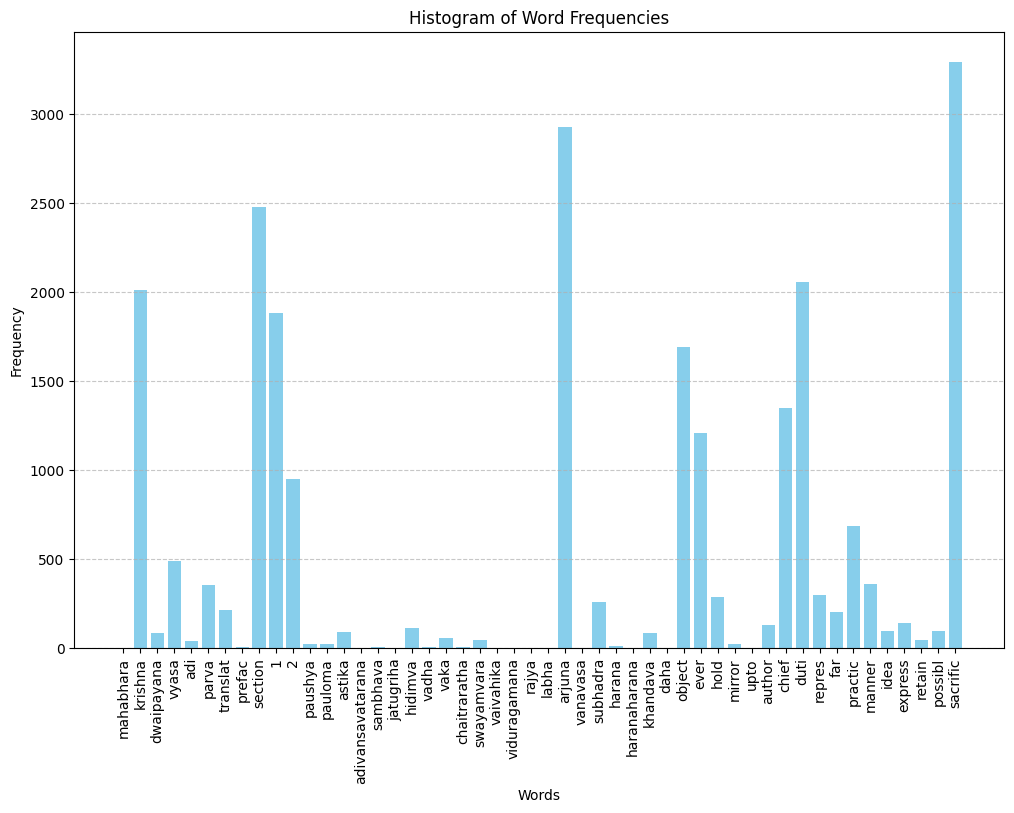

In [6]:
words = list(word_frequencies.keys())
frequencies = list(word_frequencies.values())

# Creating a histogram of word frequencies
plt.figure(figsize=(12, 8))
plt.bar(words[:50], frequencies[:50], color='skyblue')  # Plot top 50 words for clarity
plt.xticks(rotation=90)
plt.title('Histogram of Word Frequencies')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


Splitting Dataset into Training and Testing set


In [7]:
from sklearn.model_selection import train_test_split

# Splitting the tokens into training and testing sets (80% training, 20% testing)
train_tokens, test_tokens = train_test_split(tokens, test_size=0.2, random_state=42)

print(f"Training size: {len(train_tokens)}, Testing size: {len(test_tokens)}")


Training size: 2052401, Testing size: 513101


In [22]:
from collections import Counter, defaultdict
import re


In [40]:
# Load and Tokenize the Dataset
content = "... your dataset text ..."  # Load your dataset here
tokens = re.findall(r'\w+', content.lower())  # Tokenize the text by splitting on non-alphabetic characters


In [41]:
# Create N-grams Function
def create_ngrams(tokens, n):
    """Create n-grams from tokens."""
    return [tuple(tokens[i:i+n]) for i in range(len(tokens) - n + 1)]


Function to calculate N-Gram Probabilities

In [23]:
def calculate_ngram_probabilities(ngrams, unigrams):
  #Calculating conditional probabilities for n-grams.
    ngram_freq = Counter(ngrams)
    unigram_freq = Counter(unigrams)

    ngram_prob = defaultdict(lambda: defaultdict(float))
    for ngram, count in ngram_freq.items():
        prefix = ngram[:-1]  # All but the last token
        next_token = ngram[-1]
        ngram_prob[prefix][next_token] = count / unigram_freq[prefix[0]]

    return ngram_prob


### Loading and Tokenizing the Data

In [29]:
tokens = re.findall(r'\w+', content.lower())

unigram_freq = Counter(tokens)

# Checking tokens and unigrams
print("First 20 tokens:", tokens[:20])
print("Total number of tokens:", len(tokens))


First 20 tokens: ['the', 'mahabhara', 'a', 'of', 'krishna', 'dwaipayana', 'vyasa', 'adi', 'parva', 'translators', 'preface', 'section', '1', 'section', '2', 'paushya', 'parva', 'pauloma', 'parva', 'astika']
Total number of tokens: 2565502


Creating and Checking bigrams and trigrams dataset

In [25]:
def create_ngrams(tokens, n):
    """Create n-grams from tokens."""
    return [tuple(tokens[i:i+n]) for i in range(len(tokens) - n + 1)]

# Creating bigrams and trigrams
bigrams = create_ngrams(tokens, 2)
trigrams = create_ngrams(tokens, 3)

# Checkiing the first 10 bigrams and trigrams
print("First 10 bigrams:", bigrams[:10])
print("First 10 trigrams:", trigrams[:10])


First 10 bigrams: [('the', 'mahabhara'), ('mahabhara', 'a'), ('a', 'of'), ('of', 'krishna'), ('krishna', 'dwaipayana'), ('dwaipayana', 'vyasa'), ('vyasa', 'adi'), ('adi', 'parva'), ('parva', 'translators'), ('translators', 'preface')]
First 10 trigrams: [('the', 'mahabhara', 'a'), ('mahabhara', 'a', 'of'), ('a', 'of', 'krishna'), ('of', 'krishna', 'dwaipayana'), ('krishna', 'dwaipayana', 'vyasa'), ('dwaipayana', 'vyasa', 'adi'), ('vyasa', 'adi', 'parva'), ('adi', 'parva', 'translators'), ('parva', 'translators', 'preface'), ('translators', 'preface', 'section')]


Most Common Bigrams and Trigrams

In [26]:
bigram_freq = Counter(bigrams)
trigram_freq = Counter(trigrams)

# Check the most common bigrams and trigrams
print("Most common bigrams:", bigram_freq.most_common(5))
print("Most common trigrams:", trigram_freq.most_common(5))


Most common bigrams: [(('of', 'the'), 26187), (('and', 'the'), 10047), (('in', 'the'), 9896), (('to', 'the'), 6949), (('by', 'the'), 6245)]
Most common trigrams: [(('the', 'son', 'of'), 3316), (('in', 'consequence', 'of'), 1651), (('o', 'thou', 'of'), 1241), (('that', 'foremost', 'of'), 1139), (('son', 'of', 'pandu'), 1088)]


In [37]:
def predict_next_word(context, ngram_freq, lower_order_freq):
    """Predict the next word using maximum likelihood estimation."""

    context_length = len(list(ngram_freq.keys())[0]) - 1
    context_tuple = tuple(context[-context_length:])

    # Finding the possible next words and their probabilities
    possible_next_words = {}
    for ngram in ngram_freq:
        if ngram[:-1] == context_tuple:
            possible_next_words[ngram[-1]] = ngram_freq[ngram]  # Use the n-gram count directly

    # Return the most probable next word, or a fallback word if none found
    if possible_next_words:
        return max(possible_next_words, key=possible_next_words.get)

    # Fallback: Return the first word from the unigram frequency as a default prediction
    if lower_order_freq:
        return max(lower_order_freq, key=lower_order_freq.get)

    return "No prediction available"


Predicting Next word

In [38]:
next_word_bigram = predict_next_word(['son'], bigram_freq, unigram_freq)
next_word_trigram = predict_next_word(['son', 'of'], trigram_freq, bigram_freq)

print("Predicted next word (bigram):", next_word_bigram)
print("Predicted next word (trigram):", next_word_trigram)


Predicted next word (bigram): of
Predicted next word (trigram): pandu


More Test cases

In [39]:
# List of test contexts for bigram and trigram predictions
bigram_test_cases = [
    ['the'],
    ['son'],
    ['of'],
    ['and'],
    ['in'],
    ['a'],
    ['to'],
    ['that'],
    ['is'],
    ['for'],
    ['he'],
    ['she'],
    ['it'],
    ['with'],
    ['at'],
    ['this'],
    ['they'],
    ['by'],
    ['but'],
    ['as']
]

trigram_test_cases = [
    ['the', 'son'],
    ['son', 'of'],
    ['the', 'war'],
    ['the', 'king'],
    ['the', 'best'],
    ['a', 'man'],
    ['the', 'great'],
    ['to', 'be'],
    ['in', 'the'],
    ['and', 'the'],
    ['he', 'said'],
    ['she', 'was'],
    ['this', 'is'],
    ['that', 'day'],
    ['there', 'was'],
    ['with', 'her'],
    ['at', 'home'],
    ['by', 'the'],
    ['for', 'the'],
    ['from', 'the']
]

# Testing bigram predictions
print("Bigram Predictions:")
for context in bigram_test_cases:
    next_word_bigram = predict_next_word(context, bigram_freq, unigram_freq)
    print(f"Context: {context}, Predicted next word (bigram): {next_word_bigram}")

# Testing trigram predictions
print("\nTrigram Predictions:")
for context in trigram_test_cases:
    next_word_trigram = predict_next_word(context, trigram_freq, bigram_freq)
    print(f"Context: {context}, Predicted next word (trigram): {next_word_trigram}")


Bigram Predictions:
Context: ['the'], Predicted next word (bigram): son
Context: ['son'], Predicted next word (bigram): of
Context: ['of'], Predicted next word (bigram): the
Context: ['and'], Predicted next word (bigram): the
Context: ['in'], Predicted next word (bigram): the
Context: ['a'], Predicted next word (bigram): brahmana
Context: ['to'], Predicted next word (bigram): the
Context: ['that'], Predicted next word (bigram): is
Context: ['is'], Predicted next word (bigram): the
Context: ['for'], Predicted next word (bigram): the
Context: ['he'], Predicted next word (bigram): that
Context: ['she'], Predicted next word (bigram): is
Context: ['it'], Predicted next word (bigram): is
Context: ['with'], Predicted next word (bigram): the
Context: ['at'], Predicted next word (bigram): the
Context: ['this'], Predicted next word (bigram): is
Context: ['they'], Predicted next word (bigram): are
Context: ['by'], Predicted next word (bigram): the
Context: ['but'], Predicted next word (bigram): t